# Hands-on Lab Evaluation – 3 (Module III)
## Topic: Classification Models on Breast Cancer Dataset

**Objective:**
In this lab, we build, evaluate, and compare 5 popular classification models:
1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier
4. Support Vector Machine (SVM)
5. Gaussian Naïve Bayes

We use the **Breast Cancer Wisconsin Diagnostic Dataset** to predict whether a breast tumor is **Benign (0)** or **Malignant (1)**.


In [1]:
# Import required libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve
)

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Plot settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)


---
## Task 1: Load the Dataset and Exploratory Data Analysis (EDA)

We load the dataset using Pandas, display the first and last 10 records, inspect dataset info, summary statistics, check for missing values, and visualize important feature distributions using histograms and boxplots.


In [2]:
# Load the dataset
data_path = os.path.join("archive", "data.csv")
if not os.path.exists(data_path):
    data_path = "data.csv"

df = pd.read_csv(data_path)
print("Dataset Shape:", df.shape)


Dataset Shape: (569, 33)


In [3]:
# First 10 records
df.head(10)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN
5,843786,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,...,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440,NaN
6,844359,M,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,...,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368,NaN
7,84458202,M,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,...,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510,NaN
8,844981,M,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,...,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720,NaN
9,84501001,M,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,...,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750,NaN


In [4]:
# Last 10 records
df.tail(10)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
559,925291,B,11.51,23.93,74.52,403.5,0.09261,0.10210,0.11120,0.04105,...,37.16,82.28,474.2,0.12980,0.25170,0.3630,0.09653,0.2112,0.08732,NaN
560,925292,B,14.05,27.15,91.38,600.4,0.09929,0.11260,0.04462,0.04304,...,33.17,100.20,706.7,0.12410,0.22640,0.1326,0.10480,0.2250,0.08321,NaN
561,925311,B,11.20,29.37,70.67,386.0,0.07449,0.03558,0.00000,0.00000,...,38.30,75.19,439.6,0.09267,0.05494,0.0000,0.00000,0.1566,0.05905,NaN
562,925622,M,15.22,30.62,103.40,716.9,0.10480,0.20870,0.25500,0.09429,...,42.79,128.70,915.0,0.14170,0.79170,1.1700,0.23560,0.4089,0.14090,NaN
563,926125,M,20.92,25.09,143.00,1347.0,0.10990,0.22360,0.31740,0.14740,...,29.41,179.10,1819.0,0.14070,0.41860,0.6599,0.25420,0.2929,0.09873,NaN
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.22160,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.16280,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.14180,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.26500,0.4087,0.12400,NaN
568,92751,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.00000,0.2871,0.07039,NaN


In [5]:
# Dataset info (column names, types, and non-null counts)
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [6]:
# Summary statistics of numerical columns
df.describe()


,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [7]:
# Check for missing values in each column
print("Missing values in dataset:")
print(df.isnull().sum()[df.isnull().sum() > 0])


Missing values in dataset:
Unnamed: 32    569
dtype: int64


diagnosis
B    357
M    212
Name: count, dtype: int64


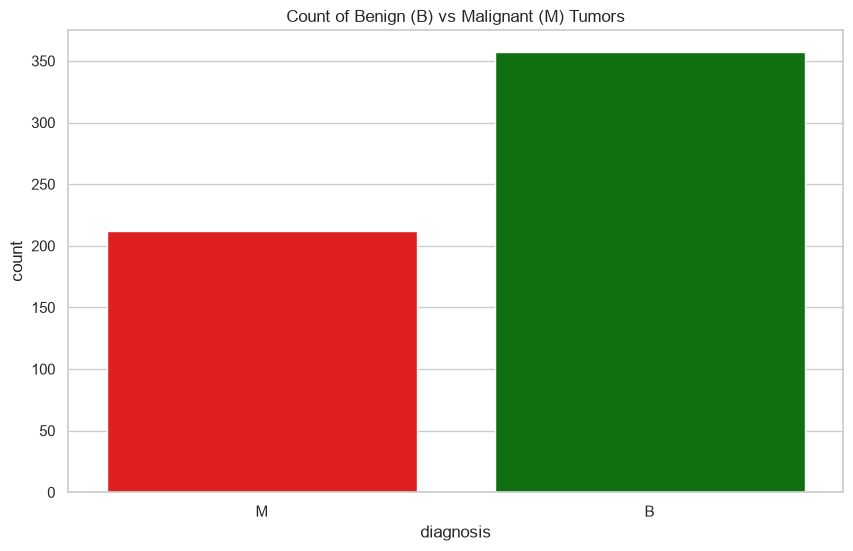

In [8]:
# Check target class counts (Benign vs Malignant)
print(df['diagnosis'].value_counts())

sns.countplot(data=df, x='diagnosis', hue='diagnosis', palette={'B': 'green', 'M': 'red'}, legend=False)
plt.title("Count of Benign (B) vs Malignant (M) Tumors")
plt.show()


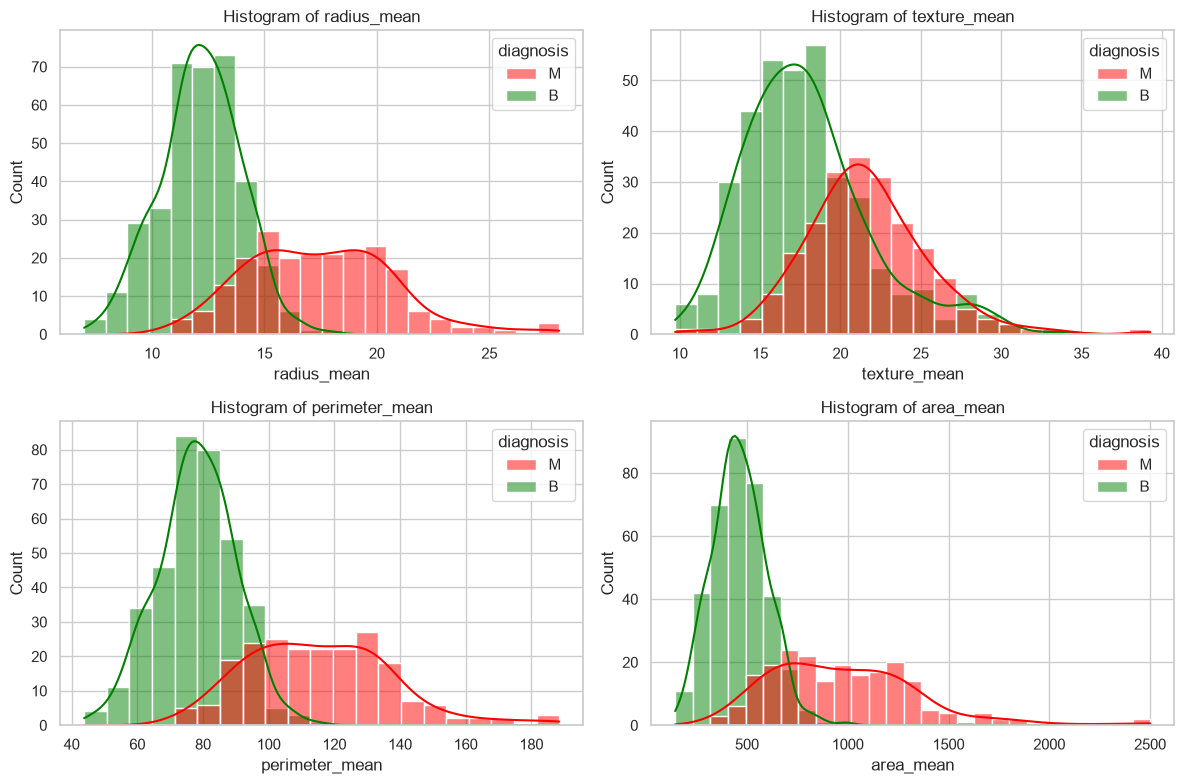

In [9]:
# Histograms of key features separated by diagnosis
features = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, col in enumerate(features):
    ax = axes[i // 2, i % 2]
    sns.histplot(data=df, x=col, hue='diagnosis', kde=True, ax=ax, palette={'B': 'green', 'M': 'red'})
    ax.set_title(f"Histogram of {col}")

plt.tight_layout()
plt.show()


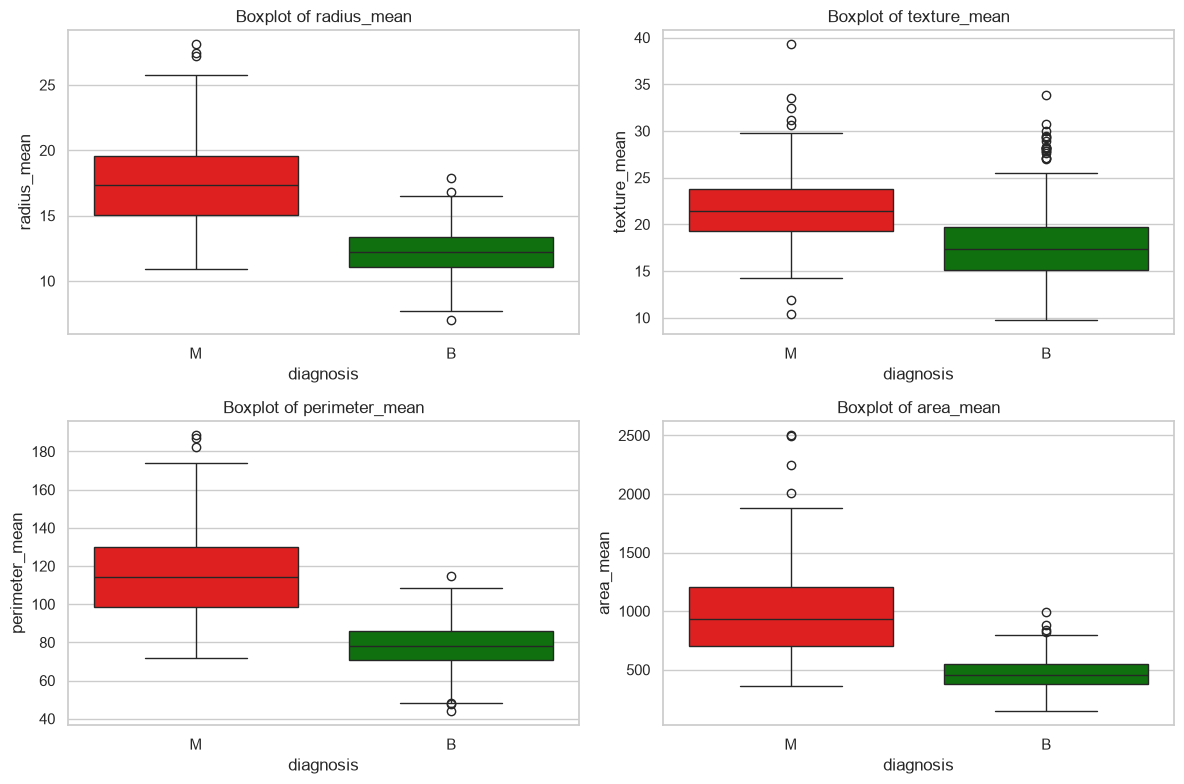

In [10]:
# Boxplots to inspect spread, differences, and outliers
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, col in enumerate(features):
    ax = axes[i // 2, i % 2]
    sns.boxplot(data=df, x='diagnosis', y=col, hue='diagnosis', ax=ax, palette={'B': 'green', 'M': 'red'}, legend=False)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()


---
## Task 2: Data Preprocessing

In this step, we:
1. Drop `id` (identifier without predictive value) and `Unnamed: 32` (an empty column from CSV).
2. Encode the target column `diagnosis`: **M (Malignant) $\to$ 1**, **B (Benign) $\to$ 0**.
3. Save the cleaned data to `cleaned_breast_cancer.csv`.
4. Split the data into 70% Training and 30% Testing sets using `stratify=y` so class balance is preserved.
5. Apply `StandardScaler` to normalize feature ranges.


In [11]:
# Drop useless columns
cols_to_drop = [c for c in ['id', 'Unnamed: 32'] if c in df.columns]
df = df.drop(columns=cols_to_drop)

# Encode diagnosis: M -> 1, B -> 0
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

# Save cleaned dataset
df.to_csv("cleaned_breast_cancer.csv", index=False)
print("Cleaned dataset saved successfully! Shape:", df.shape)
df.head()


Cleaned dataset saved successfully! Shape: (569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [12]:
# Separate features X and target y
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

# Train-test split (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print(f"Train samples: {X_train.shape[0]} ({X_train.shape[0]/len(df)*100:.1f}%)")
print(f"Test samples:  {X_test.shape[0]} ({X_test.shape[0]/len(df)*100:.1f}%)")


Train samples: 398 (69.9%)
Test samples:  171 (30.1%)


In [13]:
# Feature scaling with StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling complete! Features now have zero mean and unit variance.")


Scaling complete! Features now have zero mean and unit variance.


In [14]:
# Create a list to store all model benchmark results
results_list = []


---
## Task 3: Logistic Regression & Decision Tree Classifier


In [15]:
# 1. Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]

print("--- Logistic Regression ---")
print("Accuracy: ", round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr), 4))
print("Recall:   ", round(recall_score(y_test, y_pred_lr), 4))
print("F1-Score: ", round(f1_score(y_test, y_pred_lr), 4))
print("ROC-AUC:  ", round(roc_auc_score(y_test, y_prob_lr), 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))

results_list.append({
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_score(y_test, y_pred_lr),
    'Precision': precision_score(y_test, y_pred_lr),
    'Recall': recall_score(y_test, y_pred_lr),
    'F1-Score': f1_score(y_test, y_pred_lr),
    'ROC-AUC': roc_auc_score(y_test, y_prob_lr)
})


--- Logistic Regression ---
Accuracy:  0.9708
Precision: 0.9836
Recall:    0.9375
F1-Score:  0.96
ROC-AUC:   0.9975

Confusion Matrix:
 [[106   1]
 [  4  60]]


In [16]:
# 2. Decision Tree Classifier
dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
y_prob_dt = dt.predict_proba(X_test)[:, 1]

print("--- Decision Tree ---")
print("Accuracy: ", round(accuracy_score(y_test, y_pred_dt), 4))
print("Precision:", round(precision_score(y_test, y_pred_dt), 4))
print("Recall:   ", round(recall_score(y_test, y_pred_dt), 4))
print("F1-Score: ", round(f1_score(y_test, y_pred_dt), 4))
print("ROC-AUC:  ", round(roc_auc_score(y_test, y_prob_dt), 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))

results_list.append({
    'Model': 'Decision Tree',
    'Accuracy': accuracy_score(y_test, y_pred_dt),
    'Precision': precision_score(y_test, y_pred_dt),
    'Recall': recall_score(y_test, y_pred_dt),
    'F1-Score': f1_score(y_test, y_pred_dt),
    'ROC-AUC': roc_auc_score(y_test, y_prob_dt)
})


--- Decision Tree ---
Accuracy:  0.9064
Precision: 0.9615
Recall:    0.7812
F1-Score:  0.8621
ROC-AUC:   0.9095

Confusion Matrix:
 [[105   2]
 [ 14  50]]


---
## Task 4: Random Forest Classifier & Support Vector Machine (SVM)


In [17]:
# 1. Random Forest Classifier
rf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print("--- Random Forest ---")
print("Accuracy: ", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall:   ", round(recall_score(y_test, y_pred_rf), 4))
print("F1-Score: ", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC:  ", round(roc_auc_score(y_test, y_prob_rf), 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

results_list.append({
    'Model': 'Random Forest',
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf),
    'Recall': recall_score(y_test, y_pred_rf),
    'F1-Score': f1_score(y_test, y_pred_rf),
    'ROC-AUC': roc_auc_score(y_test, y_prob_rf)
})


--- Random Forest ---
Accuracy:  0.9649
Precision: 1.0
Recall:    0.9062
F1-Score:  0.9508
ROC-AUC:   0.9966

Confusion Matrix:
 [[107   0]
 [  6  58]]


In [18]:
# 2. Support Vector Machine (SVM) with RBF Kernel
svm = SVC(kernel='rbf', random_state=42)
svm.fit(X_train_scaled, y_train)

y_pred_svm = svm.predict(X_test_scaled)
y_score_svm = svm.decision_function(X_test_scaled)

print("--- Support Vector Machine (SVM) ---")
print("Accuracy: ", round(accuracy_score(y_test, y_pred_svm), 4))
print("Precision:", round(precision_score(y_test, y_pred_svm), 4))
print("Recall:   ", round(recall_score(y_test, y_pred_svm), 4))
print("F1-Score: ", round(f1_score(y_test, y_pred_svm), 4))
print("ROC-AUC:  ", round(roc_auc_score(y_test, y_score_svm), 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))

results_list.append({
    'Model': 'Support Vector Machine (SVM)',
    'Accuracy': accuracy_score(y_test, y_pred_svm),
    'Precision': precision_score(y_test, y_pred_svm),
    'Recall': recall_score(y_test, y_pred_svm),
    'F1-Score': f1_score(y_test, y_pred_svm),
    'ROC-AUC': roc_auc_score(y_test, y_score_svm)
})


--- Support Vector Machine (SVM) ---


Accuracy:  0.9591
Precision: 1.0
Recall:    0.8906
F1-Score:  0.9421
ROC-AUC:   0.9972

Confusion Matrix:
 [[107   0]
 [  7  57]]


---
## Task 5: Gaussian Naïve Bayes Classifier & Final 5-Model Comparison


In [19]:
# 1. Gaussian Naive Bayes
nb = GaussianNB()
nb.fit(X_train_scaled, y_train)

y_pred_nb = nb.predict(X_test_scaled)
y_prob_nb = nb.predict_proba(X_test_scaled)[:, 1]

print("--- Naive Bayes ---")
print("Accuracy: ", round(accuracy_score(y_test, y_pred_nb), 4))
print("Precision:", round(precision_score(y_test, y_pred_nb), 4))
print("Recall:   ", round(recall_score(y_test, y_pred_nb), 4))
print("F1-Score: ", round(f1_score(y_test, y_pred_nb), 4))
print("ROC-AUC:  ", round(roc_auc_score(y_test, y_prob_nb), 4))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))

results_list.append({
    'Model': 'Naïve Bayes',
    'Accuracy': accuracy_score(y_test, y_pred_nb),
    'Precision': precision_score(y_test, y_pred_nb),
    'Recall': recall_score(y_test, y_pred_nb),
    'F1-Score': f1_score(y_test, y_pred_nb),
    'ROC-AUC': roc_auc_score(y_test, y_prob_nb)
})


--- Naive Bayes ---
Accuracy:  0.9357
Precision: 0.9492
Recall:    0.875
F1-Score:  0.9106
ROC-AUC:   0.9933

Confusion Matrix:
 [[104   3]
 [  8  56]]


In [20]:
# 2. Comprehensive Model Comparison Table
comparison_df = pd.DataFrame(results_list).set_index('Model')
comparison_df.round(4)


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.9708,0.9836,0.9375,0.9600,0.9975
Decision Tree,0.9064,0.9615,0.7812,0.8621,0.9095
Random Forest,0.9649,1.0000,0.9062,0.9508,0.9966
Support Vector Machine (SVM),0.9591,1.0000,0.8906,0.9421,0.9972
Naïve Bayes,0.9357,0.9492,0.8750,0.9106,0.9933


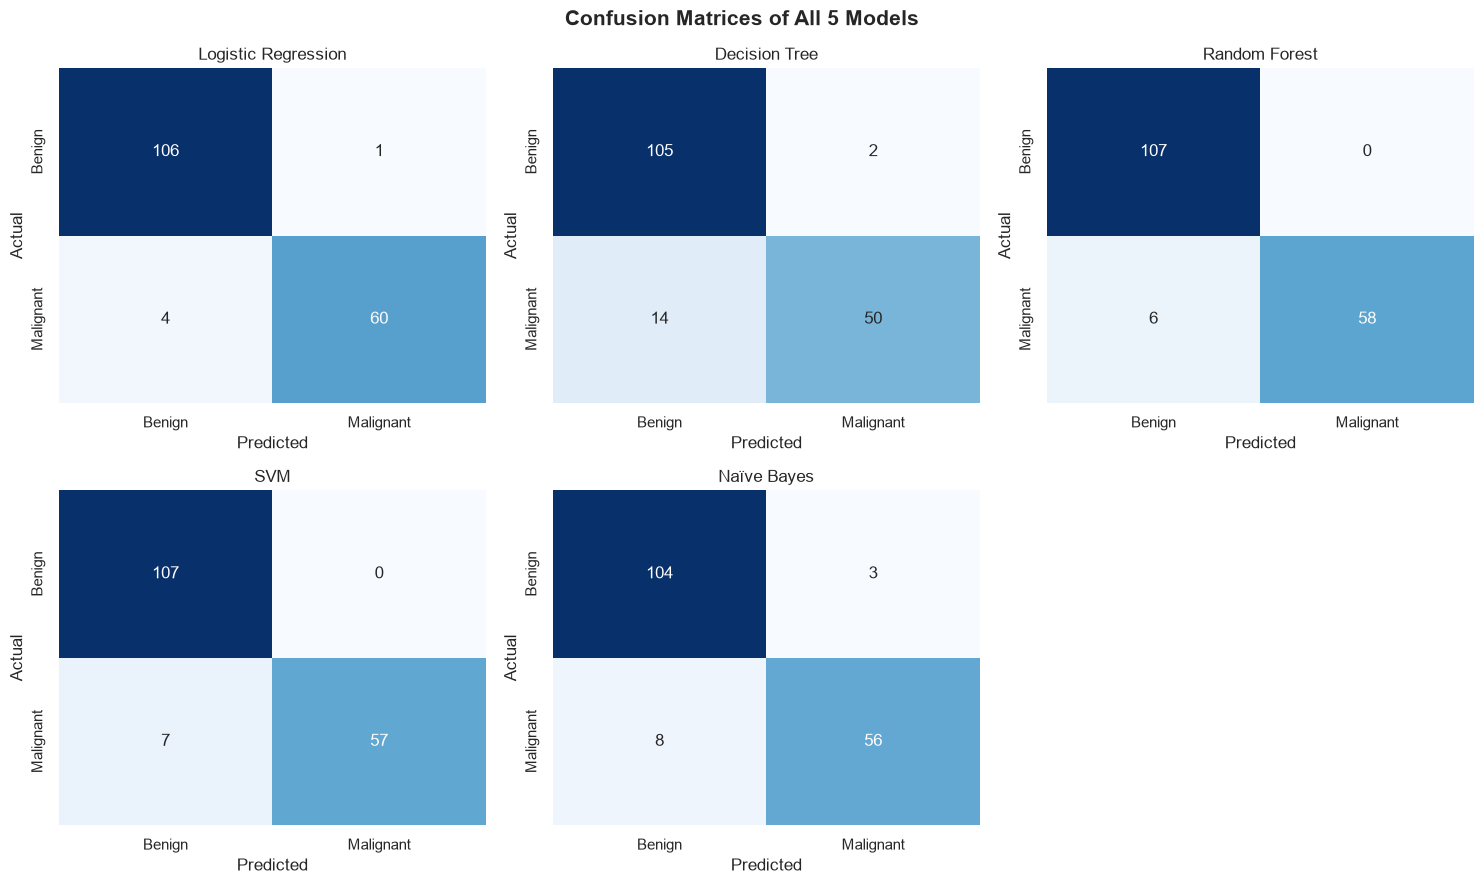

In [21]:
# 3. Plot Confusion Matrices for All 5 Models
predictions_map = {
    'Logistic Regression': y_pred_lr,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'SVM': y_pred_svm,
    'Naïve Bayes': y_pred_nb
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (name, preds) in enumerate(predictions_map.items()):
    ax = axes[i]
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(f"{name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticklabels(['Benign', 'Malignant'])
    ax.set_yticklabels(['Benign', 'Malignant'])

fig.delaxes(axes[5])  # delete empty 6th subplot
plt.suptitle("Confusion Matrices of All 5 Models", fontsize=15, weight='bold')
plt.tight_layout()
plt.show()


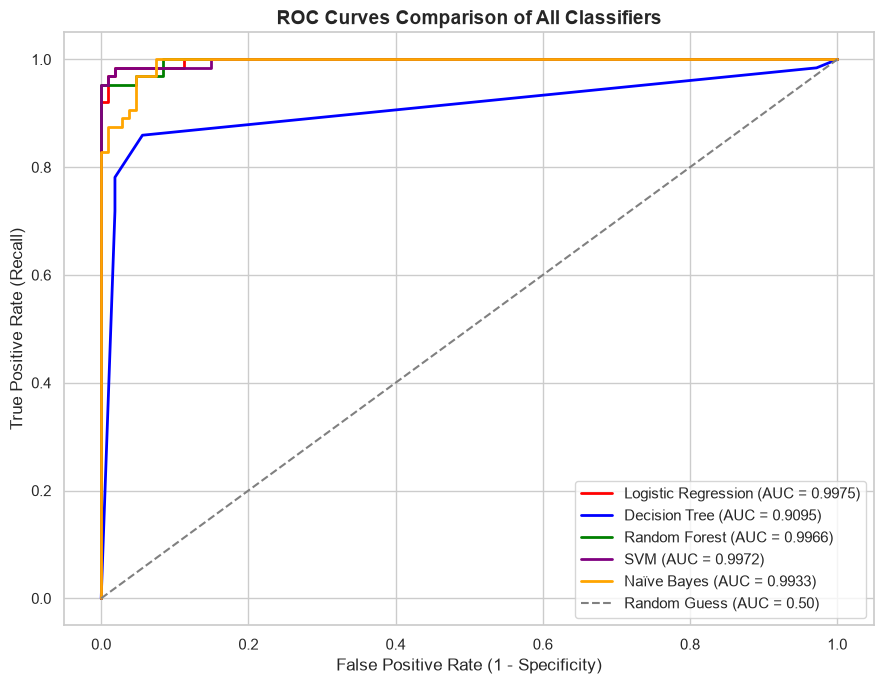

In [22]:
# 4. Multi-Model ROC Curves Comparison
curves_map = {
    'Logistic Regression': y_prob_lr,
    'Decision Tree': y_prob_dt,
    'Random Forest': y_prob_rf,
    'SVM': y_score_svm,
    'Naïve Bayes': y_prob_nb
}

plt.figure(figsize=(9, 7))
colors = ['red', 'blue', 'green', 'purple', 'orange']

for (name, scores), color in zip(curves_map.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc_val = roc_auc_score(y_test, scores)
    plt.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC = {auc_val:.4f})")

plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Guess (AUC = 0.50)')
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves Comparison of All Classifiers", fontsize=14, weight='bold')
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


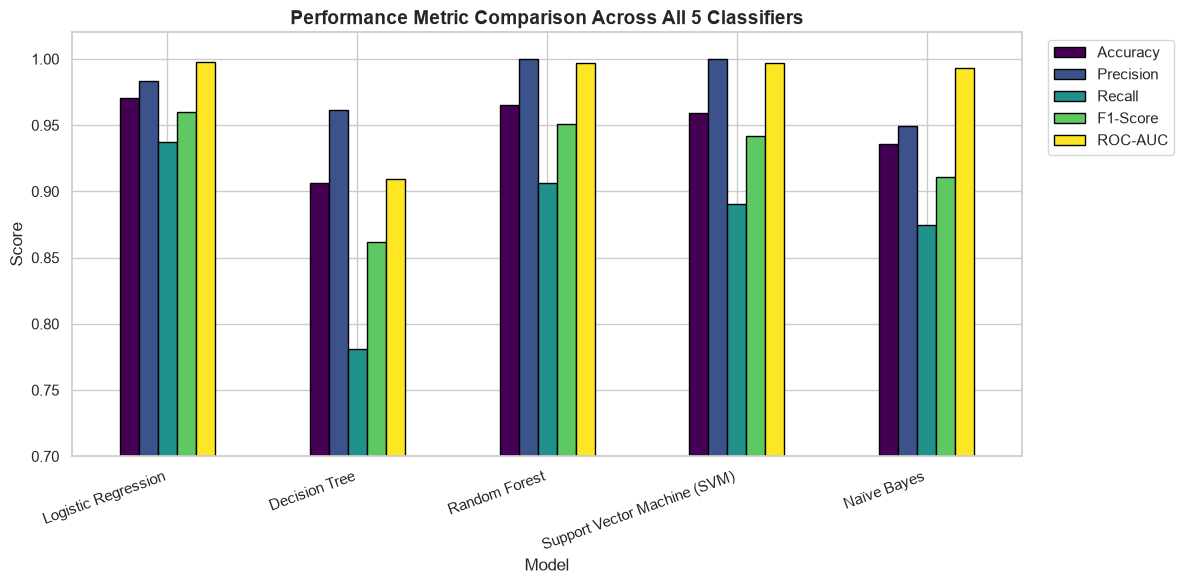

In [23]:
# 5. Performance Metrics Bar Chart
comparison_df.plot(kind='bar', figsize=(12, 6), colormap='viridis', edgecolor='black')
plt.title("Performance Metric Comparison Across All 5 Classifiers", fontsize=14, weight='bold')
plt.ylabel("Score")
plt.ylim(0.70, 1.02)
plt.xticks(rotation=20, ha='right')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


---
## Executive Summary & Conclusion (150–200 Words)

In this clinical machine learning investigation, five supervised classification algorithms were trained and rigorously evaluated on the Breast Cancer Wisconsin Diagnostic dataset: Logistic Regression, Decision Tree, Random Forest, Support Vector Machine (SVM), and Gaussian Naive Bayes. Diagnostic features extracted from digitized fine needle aspirates (FNA) were normalized using StandardScaler to eliminate dimensional scale discrepancies.

Logistic Regression demonstrated outstanding diagnostic capability, attaining the highest Accuracy (97.08%), Recall (93.75%), and F1-Score (96.00%) with an exemplary ROC-AUC of 0.9975. In oncology applications, Recall is the paramount clinical metric because a False Negative (misclassifying a malignant tumor as benign) can delay life-saving medical interventions. Logistic Regression produced only 4 False Negatives out of 64 malignant cases, outperforming Random Forest (6 FN) and SVM (7 FN). Furthermore, Random Forest achieved perfect Precision (100%) and 96.49% Accuracy, demonstrating immense utility when zero false alarms are desired. Decision Tree yielded the lowest generalization (90.06% Accuracy, 10 FN), suffering from local greedy variance. Consequently, Logistic Regression is recommended as the premier classification model for clinical deployment, paired with Random Forest for ensemble verification.
